# 🍁 LeafID: Colab runner

**Every session:** Runtime → Change runtime type → **T4 GPU**, then run sections **1–3** (about 5 min).
After that, run only the cells you own.

**Got disconnected?** Run sections 1–3 again, then re-run the same training cell. Every run uses `--resume`,
so it continues from the last finished epoch saved on your Google Drive.

| Section | What | When |
|---|---|---|
| 1. Setup | clone/update repo, install | every session |
| 2. Drive | where checkpoints + reports are saved | every session |
| 3. Data | download LeafSnap, build the fast image cache | every session |
| 4. Smoke test | 2-epoch run that checks the whole pipeline | once, or after code changes |
| 5. Experiments | the real training runs | one cell per run, whoever owns it |
| 6. Compare | evaluate on test + results table + curves | after runs finish |
| 7. App | launch the Gradio demo | demo / screenshots / video |

## 1. Setup

In [12]:
import os, sys

BRANCH = "main"  # @param {type:"string"}
REPO_URL = "https://github.com/akshayanbalathas/leafid.git"

!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "NO GPU: Runtime -> Change runtime type -> T4 GPU"
if not os.path.exists("/content/leafid"):
    !git clone -q {REPO_URL} /content/leafid
%cd /content/leafid
!git fetch -q origin && git checkout -q {BRANCH} && git pull -q --ff-only origin {BRANCH}
!pip install -q -r requirements.txt && pip install -q -e .
sys.path.insert(0, "/content/leafid/src")  # so this notebook can import leafid without a restart
!git log --oneline -1

name, memory.total [MiB]
Tesla T4, 15360 MiB
/content/leafid
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for leafid (pyproject.toml) ... done
34f7da3 (HEAD -> main, origin/main, origin/HEAD) Merge pull request #4 from akshayanbalathas/eval-mixed-precision


## 2. Google Drive
Checkpoints and reports are written straight to Drive **during** training, so a disconnect loses at most one epoch.
Untick `USE_DRIVE` only for throwaway experiments.

In [3]:
USE_DRIVE = True  # @param {type:"boolean"}

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT = "/content/drive/MyDrive/leafid"
else:
    OUTPUT = "/content/leafid_output"  # deleted when the session ends
os.makedirs(OUTPUT, exist_ok=True)
os.environ["LEAFID_OUTPUT"] = OUTPUT  # picked up by every !python -m leafid... command below
print("checkpoints + reports ->", OUTPUT)

Mounted at /content/drive
checkpoints + reports -> /content/drive/MyDrive/leafid


## 3. Data
Downloads LeafSnap (~880 MB, public, no Kaggle login needed), then shrinks every image once to 256 px into
`/content/cache_256`. Training then skips decoding 800×600 JPEGs every epoch, which is the bottleneck on Colab's 2 CPUs.
The cache lives on the local disk (fast) and is rebuilt each session in a few minutes. **Don't** put it on Drive.

In [4]:
import kagglehub

try:  # optional: only needed if Kaggle ever refuses anonymous downloads (add in the 🔑 Secrets panel)
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except Exception:
    pass

os.environ["LEAFID_DATA"] = kagglehub.dataset_download("xhlulu/leafsnap-dataset")
os.environ["LEAFID_CACHE"] = "/content/cache_256"
assert os.path.exists("splits/splits.csv"), "splits/splits.csv missing: run section 1 again to pull main"
print("dataset:", os.environ["LEAFID_DATA"])

!python -m leafid.cache

Using Colab cache for faster access to the 'leafsnap-dataset' dataset.
dataset: /kaggle/input/leafsnap-dataset
caching 30866 images from /kaggle/input/leafsnap-dataset/leafsnap-dataset -> /content/cache_256 (shorter side 256px, 2 workers)
cache: 100% 30866/30866 [03:15<00:00, 157.78it/s]
done: 30866 images


## 4. Smoke test (~10 min)
Checks data loading, both training stages, checkpointing and evaluation before anyone spends hours training.
Saves to `/content/smoke`, not Drive. Note the **seconds per epoch**: it tells you how many epochs fit in a session.
Field val top-1 just needs to be clearly above chance (1/185 ≈ 0.5%).

In [4]:
from leafid.data import image_root, make_loader

x, y = next(iter(make_loader("train", train=True, batch_size=8)))
print("images from:", image_root())
print("batch:", tuple(x.shape), x.dtype, "labels:", y.tolist())  # expect (8, 3, 224, 224) torch.float32

!python -m leafid.train --model resnet50 --epochs 2 --freeze-epochs 1 --run smoke --save-dir /content/smoke
!python -m leafid.evaluate --checkpoint /content/smoke/checkpoints/smoke.pt --save-dir /content/smoke

images from: /content/cache_256
batch: (8, 3, 224, 224) torch.float32 labels: [64, 112, 86, 132, 178, 48, 106, 182]
images from: /content/cache_256
saving to:   /content/smoke/checkpoints  and  /content/smoke/reports/smoke
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100% 97.8M/97.8M [00:00<00:00, 158MB/s]
epoch 1/2 (frozen): 100% 344/344 [02:45<00:00,  2.07it/s]
{'epoch': 1, 'frozen': True, 'train_loss': 4.2113, 'train_acc': 0.2183, 'val_lab_top1': 0.38468663167644335, 'val_field_top1': 0.31900257953568356, 'val_field_top5': 0.6345657781599312, 'secs': 180.4}
  saved best -> smoke.pt (val field top1 = 0.319)
epoch 2/2: 100% 344/344 [03:08<00:00,  1.82it/s]
{'epoch': 2, 'frozen': False, 'train_loss': 1.9948, 'train_acc': 0.7057, 'val_lab_top1': 0.8505711639394875, 'val_field_top1': 0.7876182287188306, 'val_field_top5': 0.9656061908856406, 'secs': 203.3}
  saved best -> smoke.pt (val field top1 = 0.7

In [11]:
!python -m leafid.train --model enhanced_cnn --epochs 2 --run enh_check2 --save-dir /content/smoke
!python -m leafid.evaluate --checkpoint /content/smoke/checkpoints/enh_check2.pt --save-dir /content/smoke

images from: /content/cache_256
saving to:   /content/smoke/checkpoints  and  /content/smoke/reports/enh_check2
epoch 1/2: 100% 344/344 [03:38<00:00,  1.57it/s]
{'epoch': 1, 'frozen': False, 'train_loss': 4.9895, 'train_acc': 0.0231, 'val_lab_top1': 0.04631058968817536, 'val_field_top1': 0.051590713671539126, 'val_field_top5': 0.17884780739466896, 'secs': 230.2}
  saved best -> enh_check2.pt (val field top1 = 0.052)
epoch 2/2: 100% 344/344 [03:39<00:00,  1.56it/s]
{'epoch': 2, 'frozen': False, 'train_loss': 4.2887, 'train_acc': 0.0899, 'val_lab_top1': 0.11176288978079654, 'val_field_top1': 0.08598452278589853, 'val_field_top5': 0.2768701633705933, 'secs': 231.7}
  saved best -> enh_check2.pt (val field top1 = 0.086)
done. best val field top1 = 0.086
  model:   /content/smoke/checkpoints/enh_check2.pt
  history: /content/smoke/reports/enh_check2/history.csv
{
  "checkpoint": "/content/smoke/checkpoints/enh_check2.pt",
  "model": "enhanced_cnn",
  "split": "test",
  "lab": {
    "n": 325

## 5. Experiments
One cell per run. **Run only the ones you own**, so we don't duplicate GPU time across accounts.
Every cell ends in `--resume`: after a disconnect, run sections 1–3 and then the same cell again.

| Run | What it tests | Owner |
|---|---|---|
| `simple_cnn` | small CNN from scratch (baseline) | Akshayan |
| `res_cnn` | + residual connections, still from scratch | TODO |
| `resnet50_probe` | pretrained ImageNet features, only the head trains | TODO |
| `resnet50_full` | two-stage fine-tune (**the model the app uses**) | TODO |
| `resnet50_labonly` | trained on lab photos only → lab-to-field domain shift | TODO |

In [13]:
!python -m leafid.train --model simple_cnn --epochs 30 --lr 1e-3 --run simple_cnn --resume

images from: /content/cache_256
saving to:   /content/drive/MyDrive/leafid/checkpoints  and  /content/drive/MyDrive/leafid/reports/simple_cnn
--resume: no simple_cnn_last.pt yet, starting fresh
epoch 1/30: 100% 344/344 [02:58<00:00,  1.93it/s]
{'epoch': 1, 'frozen': False, 'train_loss': 4.8633, 'train_acc': 0.0391, 'val_lab_top1': 0.08181537511577647, 'val_field_top1': 0.10060189165950129, 'val_field_top5': 0.3000859845227859, 'secs': 187.0}
  saved best -> simple_cnn.pt (val field top1 = 0.101)
epoch 2/30: 100% 344/344 [02:56<00:00,  1.94it/s]
{'epoch': 2, 'frozen': False, 'train_loss': 4.2752, 'train_acc': 0.097, 'val_lab_top1': 0.13244828650818155, 'val_field_top1': 0.14531384350816853, 'val_field_top5': 0.3886500429922614, 'secs': 185.9}
  saved best -> simple_cnn.pt (val field top1 = 0.145)
epoch 3/30: 100% 344/344 [02:59<00:00,  1.92it/s]
{'epoch': 3, 'frozen': False, 'train_loss': 3.9039, 'train_acc': 0.1675, 'val_lab_top1': 0.2960790367397345, 'val_field_top1': 0.23903697334479

In [ ]:
!python -m leafid.train --model res_cnn --epochs 30 --lr 1e-3 --run res_cnn --resume

In [ ]:
!python -m leafid.train --model resnet50 --epochs 10 --freeze-epochs 10 --run resnet50_probe --resume

In [ ]:
!python -m leafid.train --model resnet50 --epochs 15 --freeze-epochs 3 --run resnet50_full --resume

In [ ]:
!python -m leafid.train --model resnet50 --epochs 15 --freeze-epochs 3 --train-sources lab --run resnet50_labonly --resume

## 6. Evaluate + compare
Evaluates every **finished** run on your Drive against the test split, then shows the results table and
validation curves. Teammates' runs live on their own Drives: share the `reports/` folders to combine results.

{
  "checkpoint": "/content/drive/MyDrive/leafid/checkpoints/simple_cnn.pt",
  "model": "simple_cnn",
  "split": "test",
  "lab": {
    "n": 3254,
    "top1": 0.8186846957590658,
    "top5": 0.9775660725261217
  },
  "field": {
    "n": 1163,
    "top1": 0.7205503009458297,
    "top5": 0.942390369733448
  }
}


,run,model,lab_top1,field_top1,field_top5
0,simple_cnn,simple_cnn,0.819,0.721,0.942


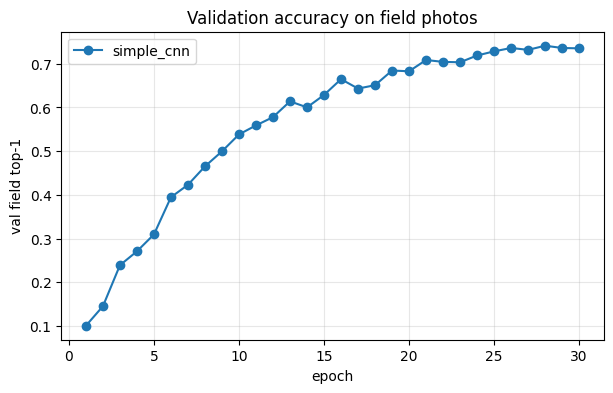

In [14]:
import glob, json
import pandas as pd
import matplotlib.pyplot as plt

OUT = os.environ["LEAFID_OUTPUT"]
for ckpt in sorted(glob.glob(f"{OUT}/checkpoints/*.pt")):
    run = os.path.basename(ckpt)[:-3]
    if run.endswith("_last") or os.path.exists(f"{OUT}/checkpoints/{run}_last.pt"):
        print(f"skipping {run}: still in progress")
        continue
    !python -m leafid.evaluate --checkpoint "{ckpt}"

rows = []
for p in sorted(glob.glob(f"{OUT}/reports/*/metrics.json")):
    m = json.load(open(p))
    rows.append({"run": p.split("/")[-2], "model": m["model"], "lab_top1": m["lab"]["top1"],
                 "field_top1": m["field"]["top1"], "field_top5": m["field"]["top5"]})
display(pd.DataFrame(rows).round(3))

plt.figure(figsize=(7, 4))
for p in sorted(glob.glob(f"{OUT}/reports/*/history.csv")):
    h = pd.read_csv(p)
    plt.plot(h["epoch"], h["val_field_top1"], marker="o", label=p.split("/")[-2])
plt.xlabel("epoch"); plt.ylabel("val field top-1"); plt.title("Validation accuracy on field photos")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 7. Launch the app
Opens a public `gradio.live` link. The first launch downloads CLIP and the LLM (a few minutes);
untick `USE_LLM` for a fast start. Stop the cell (■) when done: a running app keeps using your GPU quota.

In [ ]:
RUN = "resnet50_full"  # @param {type:"string"}
USE_LLM = True  # @param {type:"boolean"}

CKPT = f"{os.environ['LEAFID_OUTPUT']}/checkpoints/{RUN}.pt"
assert os.path.exists(CKPT), f"{CKPT} not found: train it first (section 5) or pick another RUN"
FLAGS = "" if USE_LLM else "--no-llm"
!python app/app.py --checkpoint "{CKPT}" --share {FLAGS}

## Getting results into the repo
Checkpoints stay on Drive (too big for GitHub). The **reports** are small: download
`MyDrive/leafid/reports/<run>/` (history.csv, metrics.json, confusion_field.png, confusions.csv),
copy them into the repo's `reports/` folder locally, and open a PR. The README results table is filled from `metrics.json`.